# My CNN: improving training stability

I investigate the fluctuations in my earlier CNN validation results by changing the actual training procedure. I keep the same CNN architecture, image preparation, training augmentation, random seed 42, and fixed data split. All weights are initialized randomly; I use no pretrained model.

I change only three training choices: **Adam learning rate 0.0005**, **training batch size 64**, and a **cosine learning-rate schedule over 40 planned epochs**, ending at 0.00001. My previous run used learning rate 0.001, batch 32, and 30 epochs with a constant learning rate. I keep both raw histories and compare their final 10-epoch variability. I do not smooth or edit the plotted values.

The included outputs come from executing these notebook cells. Run this notebook from the project folder after installing the requirements. `cnn_model.py` contains the unchanged model and shared image preparation.

In [1]:
from pathlib import Path
import csv, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms.functional import rotate
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
from cnn_model import build_model, prepare_image

torch.set_num_threads(4)
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
ROOT = Path.cwd()
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
RESULTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
DATASET = ROOT / "BD3_original_dataset"
if not DATASET.exists():
    DATASET = Path("/Users/daryn/Desktop/daat/BD3_original_dataset")
data = pd.read_csv(RESULTS / "split_manifest.csv").sort_values("path").reset_index(drop=True)
classes = sorted(data.label.unique())
print(pd.crosstab(data.label, data.split))

split        test  train  validation
label                               
algae          92    433          93
major_crack    86    403          87
minor_crack    87    404          86
peeling        78    360          77
plain          89    412          88
spalling       75    350          75
stain          77    363          78


## 1. Load the same training and validation subsets

I use 2,725 training images and 584 validation images. I do not load the 584 test images during this experiment. Images receive the unchanged EXIF correction, white background for transparency,96×96 bilinear resize and 0–1 RGB conversion. I cache the small images to avoid repeated decoding.

In [2]:
loaders = {}
for split in ["train", "validation"]:
    subset = data[data.split == split]
    images = []
    for path in subset.path:
        with Image.open(DATASET / path) as image:
            images.append(prepare_image(image))
    X = torch.stack(images)
    y = torch.tensor([classes.index(label) for label in subset.label])
    loaders[split] = DataLoader(TensorDataset(X, y), batch_size=64, shuffle=(split == "train"))
print("Loaded training and validation only; test images remain untouched.")

Loaded training and validation only; test images remain untouched.


## 2. Train the unchanged CNN with smaller updates

Only training batches receive random horizontal flips and rotations of up to 10 degrees, as in the earlier run. Validation uses `eval()` without augmentation. I choose the saved checkpoint using the highest validation macro F1 across all 40 planned epochs. The test set does not select the checkpoint or the revised training settings.

In [3]:
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40, eta_min=0.00001)
loss_function = nn.CrossEntropyLoss()
history = []
best_f1 = -1
print("Random-initialized CNN parameters:", sum(p.numel() for p in model.parameters()))
for epoch in range(1, 41):
    start = time.perf_counter()
    model.train()
    train_loss = 0
    train_correct = 0
    for batch, labels in loaders["train"]:
        flip = torch.rand(len(batch)) < 0.5
        batch[flip] = batch[flip].flip(-1)
        batch = rotate(batch, float(torch.empty(1).uniform_(-10, 10)))
        optimizer.zero_grad()
        output = model(batch)
        loss = loss_function(output, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(batch)
        train_correct += (output.argmax(1) == labels).sum().item()
    model.eval()
    predictions, true_labels = [], []
    validation_loss = 0
    with torch.inference_mode():
        for batch, labels in loaders["validation"]:
            output = model(batch)
            validation_loss += loss_function(output, labels).item() * len(batch)
            predictions.extend(output.argmax(1).tolist())
            true_labels.extend(labels.tolist())
    row = {"epoch": epoch, "learning_rate": optimizer.param_groups[0]["lr"],
           "train_loss": train_loss / len(loaders["train"].dataset),
           "train_accuracy": train_correct / len(loaders["train"].dataset),
           "validation_loss": validation_loss / len(loaders["validation"].dataset),
           "validation_accuracy": accuracy_score(true_labels, predictions),
           "validation_macro_f1": f1_score(true_labels, predictions, average="macro", zero_division=0),
           "seconds": round(time.perf_counter() - start, 2)}
    history.append(row)
    if row["validation_macro_f1"] > best_f1:
        best_f1 = row["validation_macro_f1"]
        torch.save(model.state_dict(), MODELS / "cnn.pt")
        (RESULTS / "cnn_best_validation.json").write_text(json.dumps(row, indent=2))
    pd.DataFrame(history).to_csv(RESULTS / "cnn_history.csv", index=False)
    scheduler.step()
    print(f"Epoch {epoch:2d}/40 | train {row['train_accuracy']:.1%} | validation {row['validation_accuracy']:.1%} | macro F1 {row['validation_macro_f1']:.4f} | loss {row['validation_loss']:.4f} | {row['seconds']:.1f}s", flush=True)
print("Training finished; checkpoint frozen by validation macro F1. Test not evaluated.")

Random-initialized CNN parameters: 361095
Epoch  1/40 | train 34.3% | validation 31.8% | macro F1 0.2937 | loss 1.7008 | 6.5s
Epoch  2/40 | train 47.8% | validation 42.6% | macro F1 0.3996 | loss 1.4697 | 6.2s
Epoch  3/40 | train 53.8% | validation 50.2% | macro F1 0.4687 | loss 1.2860 | 6.3s
Epoch  4/40 | train 58.5% | validation 47.3% | macro F1 0.4480 | loss 1.5386 | 6.2s
Epoch  5/40 | train 62.1% | validation 54.3% | macro F1 0.5326 | loss 1.2358 | 6.3s
Epoch  6/40 | train 64.6% | validation 52.7% | macro F1 0.5174 | loss 1.2806 | 6.2s
Epoch  7/40 | train 66.8% | validation 54.1% | macro F1 0.4992 | loss 1.3089 | 6.1s
Epoch  8/40 | train 67.7% | validation 53.8% | macro F1 0.5166 | loss 1.3418 | 6.1s
Epoch  9/40 | train 69.4% | validation 65.6% | macro F1 0.6405 | loss 0.9159 | 6.2s
Epoch 10/40 | train 72.1% | validation 59.2% | macro F1 0.5571 | loss 1.2082 | 6.1s
Epoch 11/40 | train 72.3% | validation 66.3% | macro F1 0.6505 | loss 0.9312 | 6.1s
Epoch 12/40 | train 73.1% | valida

## 3. Compare the raw validation stability

For each run I use its final 10 epochs, giving nine adjacent epoch changes. I measure the mean absolute change, population standard deviation, and window mean for validation accuracy, macro F1, and loss. Lower variability alone is insufficient: I also check the achieved validation performance. These are descriptive results from one fixed-seed run, not repeated-run statistical evidence.

{
  "window_epochs": 10,
  "adjacent_changes": 9,
  "standard_deviation_ddof": 0,
  "selection_uses_test": false,
  "runs": {
    "baseline": {
      "epochs": 30,
      "best_epoch": 24,
      "best_validation_macro_f1": 0.7593619909382993,
      "selected_validation_accuracy": 0.7654109589041096,
      "last10": {
        "validation_accuracy": {
          "mean": 0.7054794520547946,
          "population_std": 0.045857174633617805,
          "mean_absolute_adjacent_change": 0.05707762557077625
        },
        "validation_macro_f1": {
          "mean": 0.6908940922899215,
          "population_std": 0.05515296988853889,
          "mean_absolute_adjacent_change": 0.06715072515354169
        },
        "validation_loss": {
          "mean": 0.9120786444985705,
          "population_std": 0.21560383552658913,
          "mean_absolute_adjacent_change": 0.28981154964304046
        }
      }
    },
    "revised": {
      "epochs": 40,
      "best_epoch": 38,
      "best_validation_macro

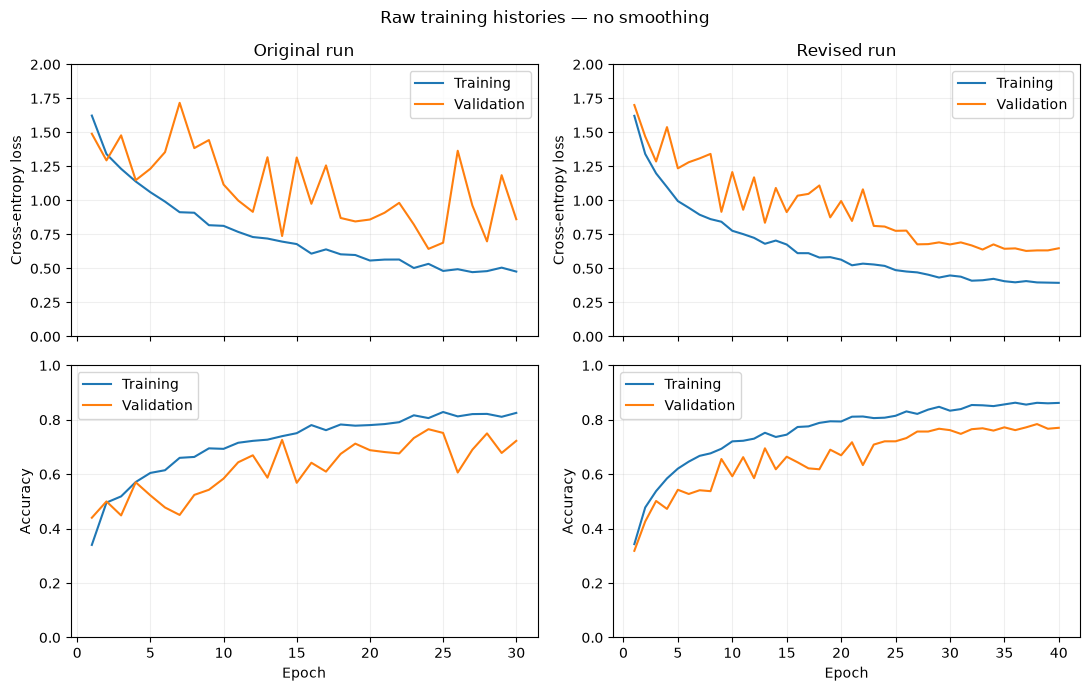

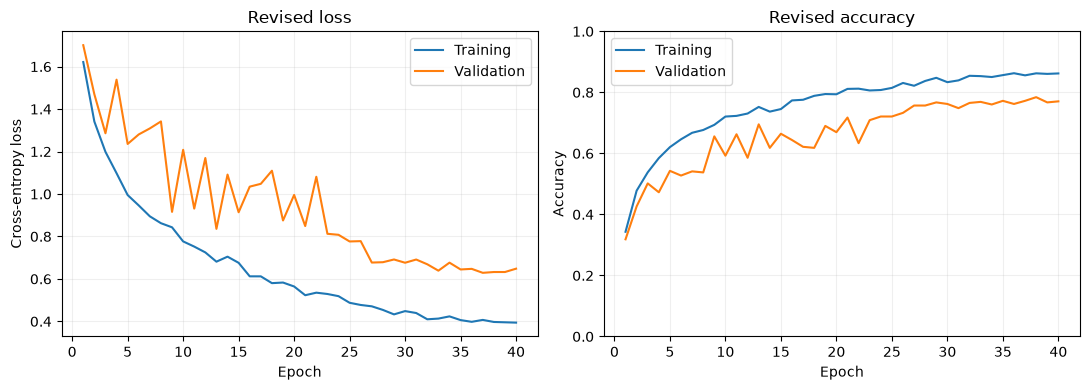

In [4]:
baseline = pd.read_csv(RESULTS / "cnn_before_stabilization_history.csv")
history = pd.read_csv(RESULTS / "cnn_history.csv")
stability = {"window_epochs": 10, "adjacent_changes": 9, "standard_deviation_ddof": 0,
             "selection_uses_test": False, "runs": {}}
for name, frame in [("baseline", baseline), ("revised", history)]:
    window = frame.tail(10)
    selected = frame.loc[frame.validation_macro_f1.idxmax()]
    result = {"epochs": len(frame), "best_epoch": int(selected.epoch),
              "best_validation_macro_f1": float(selected.validation_macro_f1),
              "selected_validation_accuracy": float(selected.validation_accuracy), "last10": {}}
    for column in ["validation_accuracy", "validation_macro_f1", "validation_loss"]:
        values = window[column].to_numpy()
        result["last10"][column] = {"mean": float(values.mean()),
            "population_std": float(values.std(ddof=0)),
            "mean_absolute_adjacent_change": float(np.abs(np.diff(values)).mean())}
    stability["runs"][name] = result
(RESULTS / "cnn_stability.json").write_text(json.dumps(stability, indent=2))
print(json.dumps(stability, indent=2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex="col")
for column, (name, frame) in enumerate([("Original run", baseline), ("Revised run", history)]):
    axes[0, column].plot(frame.epoch, frame.train_loss, label="Training")
    axes[0, column].plot(frame.epoch, frame.validation_loss, label="Validation")
    axes[0, column].set(title=name, ylabel="Cross-entropy loss", ylim=(0, 2))
    axes[1, column].plot(frame.epoch, frame.train_accuracy, label="Training")
    axes[1, column].plot(frame.epoch, frame.validation_accuracy, label="Validation")
    axes[1, column].set(xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
for ax in axes.flat:
    ax.legend()
    ax.grid(alpha=0.2)
plt.suptitle("Raw training histories — no smoothing")
plt.tight_layout()
plt.savefig(RESULTS / "cnn_stability_comparison.png", dpi=170)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.epoch, history.train_loss, label="Training")
axes[0].plot(history.epoch, history.validation_loss, label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Revised loss")
axes[1].plot(history.epoch, history.train_accuracy, label="Training")
axes[1].plot(history.epoch, history.validation_accuracy, label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Revised accuracy", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS / "cnn_training_curves.png", dpi=170)
plt.show()

## Compare the same epochs and the final training stage

I report both matched epochs 21–30 and the final 10 epochs of each run (21–30 originally, 31–40 after the change). I use the raw values in both calculations and plots. My validation acceptance checks were fixed before evaluating the revised model on the test set.

{
  "window_definition": "10 raw epochs, 9 adjacent differences; population SD uses ddof=0",
  "test_used_for_selection": false,
  "windows": {
    "matched_epochs_21_30": {
      "baseline": {
        "epoch_start": 21,
        "epoch_end": 30,
        "validation_accuracy": {
          "mean": 0.7054794520547946,
          "population_std": 0.045857174633617805,
          "mean_absolute_adjacent_change": 0.05707762557077625
        },
        "validation_macro_f1": {
          "mean": 0.6908940922899215,
          "population_std": 0.05515296988853889,
          "mean_absolute_adjacent_change": 0.06715072515354169
        },
        "validation_loss": {
          "mean": 0.9120786444985705,
          "population_std": 0.21560383552658913,
          "mean_absolute_adjacent_change": 0.28981154964304046
        }
      },
      "revised": {
        "epoch_start": 21,
        "epoch_end": 30,
        "validation_accuracy": {
          "mean": 0.7277397260273972,
          "population_std

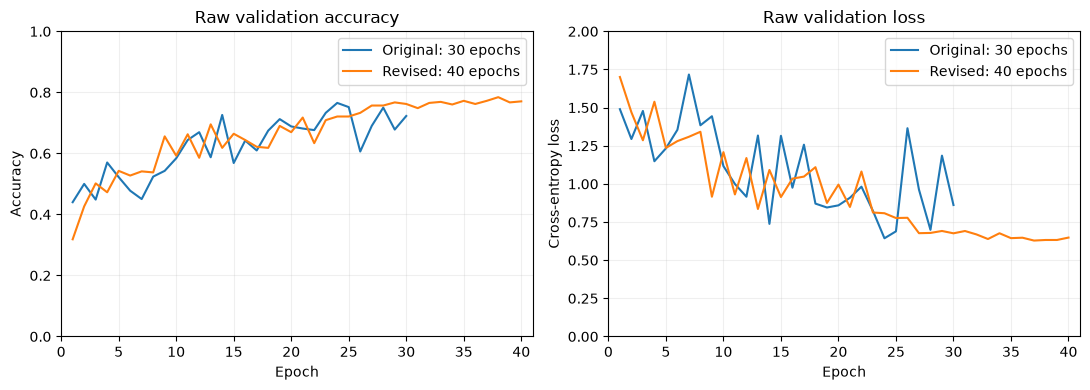

In [5]:
baseline = pd.read_csv(RESULTS / "cnn_before_stabilization_history.csv")
history = pd.read_csv(RESULTS / "cnn_history.csv")
comparison = {"window_definition": "10 raw epochs, 9 adjacent differences; population SD uses ddof=0",
              "test_used_for_selection": False, "windows": {}, "best_validation": {}}
for window_name in ["matched_epochs_21_30", "terminal_10"]:
    comparison["windows"][window_name] = {}
    for run_name, frame in [("baseline", baseline), ("revised", history)]:
        window = frame[frame.epoch.between(21, 30)] if window_name == "matched_epochs_21_30" else frame.tail(10)
        summary = {"epoch_start": int(window.epoch.min()), "epoch_end": int(window.epoch.max())}
        for column in ["validation_accuracy", "validation_macro_f1", "validation_loss"]:
            values = window[column].to_numpy()
            summary[column] = {"mean": float(values.mean()), "population_std": float(values.std(ddof=0)),
                               "mean_absolute_adjacent_change": float(np.abs(np.diff(values)).mean())}
        comparison["windows"][window_name][run_name] = summary
    reduction = {}
    for column in ["validation_accuracy", "validation_macro_f1", "validation_loss"]:
        old = comparison["windows"][window_name]["baseline"][column]["mean_absolute_adjacent_change"]
        new = comparison["windows"][window_name]["revised"][column]["mean_absolute_adjacent_change"]
        reduction[column] = 100 * (1 - new / old)
    comparison["windows"][window_name]["adjacent_change_reduction_percent"] = reduction
for name, frame in [("baseline", baseline), ("revised", history)]:
    best = frame.loc[frame.validation_macro_f1.idxmax()]
    comparison["best_validation"][name] = {"epoch": int(best.epoch), "macro_f1": float(best.validation_macro_f1),
                                            "accuracy": float(best.validation_accuracy)}
comparison["prespecified_checks"] = {
    "minimum_best_validation_macro_f1": 0.7493619909382992,
    "maximum_terminal10_accuracy_mean_absolute_change": 0.02853957382039573,
    "validation_performance_pass": comparison["best_validation"]["revised"]["macro_f1"] >= 0.7493619909382992,
    "validation_stability_pass": comparison["windows"]["terminal_10"]["revised"]["validation_accuracy"]["mean_absolute_adjacent_change"] <= 0.02853957382039573}
comparison["limitations"] = "Single fixed-seed experiment; batch size, learning rate, scheduler, and epoch budget change together. No isolated causal or formal significance claim."
(RESULTS / "cnn_stability_comparison.json").write_text(json.dumps(comparison, indent=2))
print(json.dumps(comparison, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, frame in [("Original: 30 epochs", baseline), ("Revised: 40 epochs", history)]:
    axes[0].plot(frame.epoch, frame.validation_accuracy, label=label)
    axes[1].plot(frame.epoch, frame.validation_loss, label=label)
axes[0].set(title="Raw validation accuracy", ylabel="Accuracy", ylim=(0, 1))
axes[1].set(title="Raw validation loss", ylabel="Cross-entropy loss", ylim=(0, 2))
for ax in axes:
    ax.set(xlabel="Epoch", xlim=(0, 41))
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS / "cnn_stability_comparison.png", dpi=170)
plt.show()


## Evaluate the accepted checkpoint once

My revised recipe met both prespecified validation checks: best validation macro F1 at least 0.74936 and final-ten mean absolute accuracy change at most 0.02854. I accepted the recipe and froze epoch 38 using validation alone, then evaluated the 584 test images once. I did not change the model after seeing this test result. This is still the same image-level test split used in earlier experiments, not a new independent dataset.

Test accuracy: 81.16% (474 / 584)
Test macro F1: 0.8085
              precision    recall  f1-score   support

       algae     0.9368    0.9674    0.9519        92
 major_crack     0.8101    0.7442    0.7758        86
 minor_crack     0.6224    0.7011    0.6595        87
     peeling     0.8333    0.7051    0.7639        78
       plain     0.9140    0.9551    0.9341        89
    spalling     0.8831    0.9067    0.8947        75
       stain     0.6842    0.6753    0.6797        77

    accuracy                         0.8116       584
   macro avg     0.8120    0.8078    0.8085       584
weighted avg     0.8138    0.8116    0.8113       584



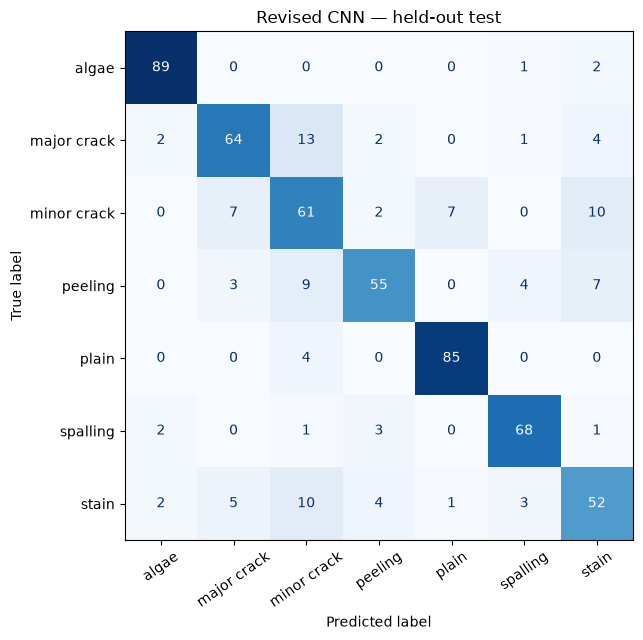

In [6]:
from sklearn.metrics import precision_score, recall_score, balanced_accuracy_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

best = json.loads((RESULTS / "cnn_best_validation.json").read_text())
history = pd.read_csv(RESULTS / "cnn_history.csv")
test_data = data[data.split == "test"]
images = []
for path in test_data.path:
    with Image.open(DATASET / path) as image:
        images.append(prepare_image(image))
X_test = torch.stack(images)
y_test = np.array([classes.index(label) for label in test_data.label])
model = build_model()
model.load_state_dict(torch.load(MODELS / "cnn.pt", map_location="cpu", weights_only=True))
model.eval()
start = time.perf_counter()
scores = []
with torch.inference_mode():
    for batch in X_test.split(64):
        scores.append(model(batch).softmax(1).numpy())
predict_seconds = time.perf_counter() - start
probabilities = np.concatenate(scores)
prediction = probabilities.argmax(1)
matrix = confusion_matrix(y_test, prediction, labels=range(7))
report = classification_report(y_test, prediction, labels=range(7), target_names=classes, output_dict=True, zero_division=0)
metrics = {"model": "CNN trained from scratch", "pretrained": False,
    "parameter_count": sum(p.numel() for p in model.parameters()), "epochs_planned": 40,
    "best_epoch": best["epoch"], "classes": classes, "validation_accuracy": best["validation_accuracy"],
    "validation_macro_f1": best["validation_macro_f1"], "checkpoint_selection": "highest validation macro F1 across 40 planned epochs",
    "split_counts": {"train": 2725, "validation": 584, "test": len(y_test)},
    "test_accuracy": accuracy_score(y_test, prediction),
    "test_precision_macro": precision_score(y_test, prediction, average="macro", zero_division=0),
    "test_recall_macro": recall_score(y_test, prediction, average="macro", zero_division=0),
    "test_macro_f1": f1_score(y_test, prediction, average="macro", zero_division=0),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, prediction),
    "correct_count": int((prediction == y_test).sum()), "fit_seconds": float(history.seconds.sum()),
    "predict_seconds": predict_seconds, "classification_report": report, "confusion_matrix": matrix.tolist(),
    "timing_note": "Epoch time includes training and validation; prediction excludes image loading/preprocessing.",
    "training_settings": {"optimizer": "Adam", "learning_rate": 0.0005, "loss": "CrossEntropyLoss", "batch_size": 64,
        "scheduler": "cosine decay over40 epochs, minimum lr0.00001", "seed": 42, "image_size": [96, 96],
        "augmentation": "unchanged training-only horizontal flip and random rotation ±10 degrees"},
    "stabilization_comparison_file": "results/cnn_stability_comparison.json",
    "baseline_metrics_file": "results/cnn_before_stabilization_metrics.json",
    "selection_note": "The revised recipe passed prespecified validation performance and stability checks before this test evaluation.",
    "test_reuse_note": "This fixed split was evaluated for earlier models. It did not select the revised CNN recipe or checkpoint."}
(RESULTS / "cnn_metrics.json").write_text(json.dumps(metrics, indent=2))
np.save(RESULTS / "cnn_test_probabilities.npy", probabilities)
test_results = test_data[["path", "label"]].copy().rename(columns={"label": "true_label"})
test_results["predicted_label"] = [classes[index] for index in prediction]
for index, label in enumerate(classes):
    test_results["prob_" + label] = probabilities[:, index]
test_results.to_csv(RESULTS / "cnn_test_predictions.csv", index=False)
print(f"Test accuracy: {metrics['test_accuracy']:.2%} ({metrics['correct_count']} / {len(y_test)})")
print(f"Test macro F1: {metrics['test_macro_f1']:.4f}")
print(classification_report(y_test, prediction, target_names=classes, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 6.5))
ConfusionMatrixDisplay(matrix, display_labels=[label.replace("_", " ") for label in classes]).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35)
ax.set_title("Revised CNN — held-out test")
plt.tight_layout()
plt.savefig(RESULTS / "cnn_confusion_matrix.png", dpi=180)
plt.show()


## Update my website

The website loads my selected weights from `models/cnn.pt`. I update only the existing CNN entry and leave the other models available. I keep the original raw history and metrics so my stability comparison remains checkable. If I rerun training, I should update the report to reflect the new results.

In [7]:
name = "CNN trained from scratch"
metrics = json.loads((RESULTS / "cnn_metrics.json").read_text())
registry_path = ROOT / "models/registry.json"
registry = json.loads(registry_path.read_text()) if registry_path.exists() else {}
registry[name] = {"type": "cnn", "file": "models/cnn.pt", "test_accuracy": metrics["test_accuracy"], "classes": metrics["classes"]}
registry_path.write_text(json.dumps(registry, indent=2))
row = {"Model": name, "Accuracy": metrics["test_accuracy"], "Precision macro": metrics["test_precision_macro"],
       "Recall macro": metrics["test_recall_macro"], "F1 macro": metrics["test_macro_f1"],
       "Balanced accuracy": metrics["test_balanced_accuracy"], "Development accuracy": np.nan,
       "Fit seconds": metrics["fit_seconds"], "Predict seconds": metrics["predict_seconds"]}
comparison_path = RESULTS / "model_comparison.csv"
comparison = pd.read_csv(comparison_path) if comparison_path.exists() else pd.DataFrame(columns=row)
comparison = comparison[comparison.Model != name]
comparison = pd.concat([comparison, pd.DataFrame([row])], ignore_index=True) if not comparison.empty else pd.DataFrame([row])
comparison.to_csv(comparison_path, index=False)
print("Updated only the CNN website entry and comparison row.")

Updated only the CNN website entry and comparison row.
